# 05. Causal alert selection under a fixed alert budget

Given the same V+F score, the same 4% price-only crash catalog, an annual budget of B = 240 alerts and a calendar-month cap of 20, I ask whether an online choice of which candidate to emit improves recall before the 1% onset compared with issuing the earliest eligible candidate.

- I use the one-minute Binance spot BTCUSDT cache of notebook 01 and the price-only crash catalog of notebook 02. I fit the model on 2021, calibrate on 2022 and evaluate on 2023-01 to 2026-04.
- I compare four policies and add no new predictive features: (1) the first eligible candidate, (2) a stricter absolute score, (3) a 7-day past-only score surprise, (4) a 60-minute past-only peak breakout. I calibrate each policy on 2022 to 240 alerts without event labels.
- This analysis is retrospective and exploratory. I have examined the 2023 to April 2026 period repeatedly, so confirmatory claims would need a new evaluation period.
- I write the results to `causal_alert_selection_v1/`, including `spot_reference.json`, the spot reference values that notebooks 06 and 07 reproduce.


## Endpoints and limits

- Primary endpoint: the number of distinct 4%-breach events with an emitted alert 30–240 minutes before the breach and before the first 1% onset. Secondary: any alert 30–240 minutes before the breach, realized alert burden, alert precision and stability by year. No selection uses test labels or future prices.
- I fix the three challengers in this notebook and do not tune them on test labels.
- The hindsight oracle of notebook 04 is an upper bound for its own threshold and constraints, not a causal benchmark or a guaranteed attainable objective.
- All policies enforce the same quota constraints, and I calibrate each to 240 alerts in 2022. They need not emit the same number of alerts from 2023 on, so I report alert counts and efficiency together.

In [2]:
from pathlib import Path
from collections import defaultdict
import json, hashlib, math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import binomtest
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from IPython.display import display

try:
    import pyarrow
except ImportError:
    import subprocess, sys
    subprocess.check_call([sys.executable, '-m', 'pip', '-q', 'install', 'pyarrow'])
    import pyarrow

try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    print('Not in Colab; BASE must point to a local copy of the results folder.')

BASE = Path('/content/drive/MyDrive/btc_lead_cost_results_77months_spot')
# --- SPOT guard: this notebook may only read the spot cache built and fingerprint-verified by notebook 1 ---
import json as _json
_src_file = BASE/'cache'/'DATA_SOURCE.json'
if not _src_file.is_file() or _json.loads(_src_file.read_text()).get('venue') != 'spot':
    raise RuntimeError(f'Not a spot cache: {_src_file} is missing or venue!=spot. Run notebook 1 (1_..._SPOT) to the end first.')
print('SPOT cache verified:', _json.loads(_src_file.read_text())['market'])

SIGNALS = BASE / 'cache' / 'btc_signals_1m.parquet'
PRICE = BASE / 'cache' / 'BTCUSDT_1m_regularized.parquet'
CATALOG = BASE / 'event_definition_eligibility_audit' / 'price_only_event_catalog.csv'
OUT = BASE / 'causal_alert_selection_v1'
OUT.mkdir(parents=True, exist_ok=True)
for p in [SIGNALS, PRICE, CATALOG]:
    if not p.exists(): raise FileNotFoundError(str(p))

B=240; MONTH_CAP=20; COOLDOWN=240; LEAD_MIN=30; LEAD_MAX=240
NS=60*10**9
SPEC=dict(model='V+F, 2021 only', threshold_calibration='2022 only, no event labels',
          test='2023-01-01 through 2026-04-30 exploratory, previously inspected',
          event='price-only 4% / 24h refractory, 5min confirmation',
          alert_budget_annual=B, calendar_month_cap=MONTH_CAP, cooldown_minutes=COOLDOWN,
          primary_endpoint='alert precedes 1% onset and is 30-240 min before 4% breach',
          policies=['first_eligible','absolute_high_score','relative_surprise_7d','past_peak_breakout_1h'],
          selection_tuning='no labels in 2022; minimize abs(alerts-240), then strictest cutoff',
          cannot_claim='no prospective validation; equal quota != equal realized count')
(OUT/'alert_selection_spec.json').write_text(json.dumps(SPEC,indent=2))
(OUT/'alert_selection_spec.sha256').write_text(
    hashlib.sha256((OUT/'alert_selection_spec.json').read_bytes()).hexdigest()+'  alert_selection_spec.json\n')
print('Output:',OUT)

Mounted at /content/drive
SPOT cache verified: Binance spot BTCUSDT 1m klines
Output: /content/drive/MyDrive/btc_lead_cost_results_77months_spot/causal_alert_selection_v1


## 1. Baseline score (no price labels in alert selection)

As in notebook 04, I fit a logistic regression on z_vol and tsr on 2021, calibrate the score on 2022 and run an exploratory evaluation from 2023, without the low-volatility filter.

In [3]:
sig = pd.read_parquet(SIGNALS,columns=['z_vol','tsr','z_hs','price_lowvol']).sort_index()
px = pd.read_parquet(PRICE,columns=['close','volume']).sort_index()
assert sig.index.equals(px.index), 'Caches must share the regular 1-minute timeline'
idx = pd.DatetimeIndex(sig.index)
if idx.tz is None: raise ValueError('UTC timezone-aware index required')
idx=idx.tz_convert('UTC')
assert idx.is_monotonic_increasing and not idx.has_duplicates
assert (np.diff(idx.asi8)==NS).all()
T=idx.asi8
v=sig.z_vol.to_numpy(dtype=float); f=sig.tsr.to_numpy(dtype=float)
h=sig.z_hs.to_numpy(dtype=float)
close=px.close.to_numpy(dtype=float); volume=px.volume.to_numpy(dtype=float)
valid=(np.isfinite(close)&(close>0)&np.isfinite(volume)&(volume>0)&
       np.isfinite(v)&np.isfinite(f)&np.isfinite(h)&(f>=0)&(f<=1))
E=pd.read_csv(CATALOG)
for c in ['breach_utc','onset_1pct_utc','confirmed_utc']:
    E[c]=pd.to_datetime(E[c],utc=True)
E=E.sort_values('breach_utc').reset_index(drop=True)
assert E.event_id.is_unique
breaches=E.breach_utc.astype('int64').to_numpy()
pos=np.searchsorted(breaches,T+LEAD_MIN*NS,'left')
y=np.zeros(len(T),dtype=np.int8)
ok=pos<len(breaches)
y[ok]=(breaches[pos[ok]]<=T[ok]+LEAD_MAX*NS).astype('int8')
train=valid&(T>=pd.Timestamp('2021-01-01',tz='UTC').value)&(T<pd.Timestamp('2022-01-01',tz='UTC').value-(LEAD_MAX+5)*NS)
cal=valid&(T>=pd.Timestamp('2022-01-01',tz='UTC').value)&(T<pd.Timestamp('2023-01-01',tz='UTC').value)
eval_mask=valid&(T>=pd.Timestamp('2023-01-01',tz='UTC').value)&(T<pd.Timestamp('2026-05-01',tz='UTC').value)
assert train.any() and cal.any() and eval_mask.any() and 0<y[train].sum()<train.sum()
clf=make_pipeline(StandardScaler(),LogisticRegression(C=0.2,class_weight='balanced',
                          max_iter=400,solver='lbfgs',random_state=17))
X=np.column_stack((v,f))
clf.fit(X[train],y[train])
# Scores are causal functions of contemporaneous precomputed features. Verify feature construction upstream.
S=np.full(len(T),np.nan,dtype=float)
S[valid]=clf.predict_proba(X[valid])[:,1]
SC_CAL=S[cal]; T_CAL=T[cal]; SC_EVAL=S[eval_mask]; T_EVAL=T[eval_mask]
EVENTS=E[(E.breach_utc>=pd.Timestamp('2023-01-01 04:00',tz='UTC'))&
         (E.breach_utc<pd.Timestamp('2026-05-01',tz='UTC'))].reset_index(drop=True)
print('2021 training valid:',int(train.sum()),'2022 calibration:',len(T_CAL),
      '2023-Apr 2026 evaluation:',len(T_EVAL),'events:',len(EVENTS))
assert len(EVENTS)>0
print('Spot primary-period events (futures data: 84):',len(EVENTS))

2021 training valid: 524087 2022 calibration: 525600 2023-Apr 2026 evaluation: 1750857 events: 83
Spot primary-period events (futures data: 84): 83


## 2. Causal selection rules and online quota scheduler

I make each emit decision at the current score timestamp, without access to later scores. The 7-day comparison uses only complete days before the current day, and the 1-hour comparison uses only past minutes.

In [4]:
def emit_calendar(t,eligible,B=240,cap=20,cooldown_min=240):
    t=np.asarray(t,dtype=np.int64)
    eligible=np.asarray(eligible,dtype=bool)
    assert len(t)==len(eligible) and np.all(np.diff(t)>0)
    ids=np.flatnonzero(eligible)
    z=[]; mcount=0; ycount=0; pm=None; py=None; last=-(10**20)
    for k in ids:
        ti=int(t[k]); dt=pd.Timestamp(ti,tz='UTC')
        year=int(dt.year); month=year*12+int(dt.month)
        if year!=py: ycount=0; py=year
        if month!=pm: mcount=0; pm=month
        if ycount>=B or mcount>=cap or ti-last<cooldown_min*NS:continue
        z.append(ti); last=ti; ycount+=1; mcount+=1
    return np.asarray(z,dtype=np.int64)

def match_events(events,alerts):
    alerts=np.sort(np.asarray(alerts,dtype=np.int64))
    out=[];used=set()
    for ev in events.itertuples(index=False):
        breach=ev.breach_utc.value; onset=ev.onset_1pct_utc.value
        left=int(np.searchsorted(alerts,breach-LEAD_MAX*NS,'left'))
        right=int(np.searchsorted(alerts,breach-LEAD_MIN*NS,'right'))
        for j in range(left,right):
            if j not in used:
                used.add(j)
                out.append(dict(event_id=int(ev.event_id),breach_utc=ev.breach_utc,
                                alarm_utc=pd.Timestamp(int(alerts[j]),tz='UTC'),
                                lead_min=(breach-int(alerts[j]))/NS,
                                pre1pct=bool(alerts[j]<onset)))
                break
    return pd.DataFrame(out,columns=['event_id','breach_utc','alarm_utc','lead_min','pre1pct'])

def statistics(events,alerts):
    hits=match_events(events,alerts)
    n=len(alerts);N=len(events)
    return dict(alarms=n,caught=len(hits),before_1pct=int(hits.pre1pct.sum()),
                false_alarms=n-len(hits),recall=len(hits)/N,
                pre_onset_recall=int(hits.pre1pct.sum())/N,
                alert_precision=(len(hits)/n if n else 0))

# Scheduler unit tests (including month/year and cooldown)
small=pd.date_range('2022-01-01',periods=48,freq='h',tz='UTC').asi8
out=emit_calendar(small,np.ones(len(small),bool),B=12,cap=1,cooldown_min=240)
assert len(out)==1
assert len(emit_calendar(small,np.zeros(len(small),bool),B=12,cap=1))==0
assert np.all(np.diff(emit_calendar(small,np.ones(len(small),bool),B=12,cap=8))>=4*60*NS)
print('Online scheduler tests OK')

Online scheduler tests OK


In [5]:
# 2022 absolute fixed-score calibration scans the same quantile grid as the preceding study.
Q=np.unique(np.r_[0.,np.linspace(.10,.995,33),.997,.999,.9999,1.])
BASE_GRID=np.unique(np.r_[np.nextafter(SC_CAL.min(),-np.inf),
                            np.quantile(SC_CAL,Q),np.nextafter(SC_CAL.max(),np.inf)])

def calibrate_grid(name,entries):
    # entries: iterable of (parameter, eligible_cal); all entries examined on 2022, no outcomes.
    rows=[]
    for param,mask in entries:
        mask=np.asarray(mask,dtype=bool)
        alerts=emit_calendar(T_CAL,mask,B,MONTH_CAP,COOLDOWN)
        rows.append(dict(policy=name,param=param,cal_alerts=len(alerts),
                         raw_candidates=int(mask.sum())))
    df=pd.DataFrame(rows)
    # Match the budget if possible, then stricter (fewer raw candidates) when tied.
    best=df.sort_values(['cal_alerts','raw_candidates'],ascending=[False,True])
    reachable=best[best.cal_alerts<=B]
    choose=(reachable if not reachable.empty else best).iloc[0]
    # The cap prevents >B; choose the policy that gets closest to B, then fewest candidates.
    maxct=int(df.cal_alerts.max()); choices=df[df.cal_alerts==maxct]
    choose=choices.sort_values('raw_candidates').iloc[0]
    return choose,df

base_choice,base_table=calibrate_grid('first_eligible',
  [(float(th), SC_CAL>=float(th)) for th in BASE_GRID])
BASE_TH=float(base_choice.param)
print('Baseline 2022 floor threshold:',BASE_TH,'alerts:',int(base_choice.cal_alerts))
# For comparison only: the baseline threshold on futures data.
print('Futures baseline threshold for comparison: 0.6710872; the spot value above is calibrated on spot 2022 scores and is expected to differ.')

Baseline 2022 floor threshold: 0.6698990591069133 alerts: 240
Futures baseline threshold for comparison: 0.6710872; the spot value above is calibrated on spot 2022 scores and is expected to differ.


In [6]:
# Generate historical (past-only) 7d score percentile thresholds for each UTC calendar day.
# No future scores, labels, or intraday maximum can enter an alert decision.
RELATIVE_Q=np.array([.975,.99,.995,.9975,.999,.9995,.99975,.9999])
TMIN=T[valid]; SMIN=S[valid]
dates=pd.to_datetime(TMIN,utc=True).floor('D')
unique_days, day_index=np.unique(dates.asi8,return_inverse=True)
lookup=np.full((len(unique_days),len(RELATIVE_Q)),np.nan,dtype=float)
for d,day in enumerate(unique_days):
    left=np.searchsorted(TMIN,day-7*24*60*NS,'left')
    right=np.searchsorted(TMIN,day,'left')  # strictly before today's midnight
    if right-left>=2*24*60:
        lookup[d]=np.quantile(SMIN[left:right],RELATIVE_Q)
# Map daily past-only percentiles to every valid minute.
REL=np.full((len(T),len(RELATIVE_Q)),np.nan,dtype=np.float32)
REL[valid]=lookup[day_index].astype(np.float32)
# Note: 2021 scores may be used to warm up the first days of 2022; never outcomes.
PREV_1H_MAX=pd.Series(S).shift(1).rolling(window=60,min_periods=15).max().to_numpy()
assert np.all(np.isnan(PREV_1H_MAX[:15]))
print('Past-only daily quantiles:',len(unique_days),'days; 1-hour past-peak arrays ready.')

Past-only daily quantiles: 2297 days; 1-hour past-peak arrays ready.


In [7]:
# Select 2022 policy parameters without inspecting any 2023+ outcome.
absq=np.unique(np.r_[.95,.97,.98,.99,.995,.9975,.999,.9995,.99975,.9999,.99995,.99999])
abs_cuts=np.unique(np.maximum(BASE_TH,np.quantile(SC_CAL,absq)))
abs_choice,abs_tbl=calibrate_grid('absolute_high_score',
            [(float(c),SC_CAL>=c) for c in abs_cuts])

rel_choice,rel_tbl=calibrate_grid('relative_surprise_7d',[
    (float(q), (SC_CAL>=BASE_TH)&(SC_CAL>=REL[cal,j]))
    for j,q in enumerate(RELATIVE_Q)])

BREAKOUT_DELTAS=[0.,.001,.002,.005,.01,.02,.04,.08]
break_choice,break_tbl=calibrate_grid('past_peak_breakout_1h',[
    (float(d), (SC_CAL>=BASE_TH)&(SC_CAL>=PREV_1H_MAX[cal]+d))
    for d in BREAKOUT_DELTAS])

choices=pd.DataFrame([base_choice,abs_choice,rel_choice,break_choice]).reset_index(drop=True)
cal_grid=pd.concat([base_table,abs_tbl,rel_tbl,break_tbl],ignore_index=True)
choices.to_csv(OUT/'selected_rules_from_2022.csv',index=False)
cal_grid.to_csv(OUT/'calibration_grid_2022.csv',index=False)
display(choices)
assert choices.policy.nunique()==4

,policy,param,cal_alerts,raw_candidates
0,first_eligible,0.669899,240,32029
1,absolute_high_score,0.686478,237,26280
2,relative_surprise_7d,0.975000,236,14389
3,past_peak_breakout_1h,0.005000,240,2085


## 3. The 2022 selection rules on the repeatedly inspected historical period

The decision time is the time of the scored candidate. `relative_surprise_7d` uses only scores from earlier complete days, and `past_peak_breakout_1h` compares with the *previous* 60 minutes.

In [8]:
selected={r.policy:float(r.param) for r in choices.itertuples()}
base=selected['first_eligible']; abs_min=selected['absolute_high_score']
q=selected['relative_surprise_7d']; qcol=int(np.argmin(np.abs(RELATIVE_Q-q)))
delta=selected['past_peak_breakout_1h']
policy_masks={
    'first_eligible': SC_EVAL>=base,
    'absolute_high_score': SC_EVAL>=abs_min,
    'relative_surprise_7d': (SC_EVAL>=base)&(SC_EVAL>=REL[eval_mask,qcol]),
    'past_peak_breakout_1h': (SC_EVAL>=base)&(SC_EVAL>=PREV_1H_MAX[eval_mask]+delta),
}
rows=[];alarm_by_policy={};matched_by_policy={};
for policy,mask in policy_masks.items():
    alarm=emit_calendar(T_EVAL,mask,B,MONTH_CAP,COOLDOWN)
    alarm_by_policy[policy]=alarm
    matched_by_policy[policy]=match_events(EVENTS,alarm)
    st=statistics(EVENTS,alarm)
    rows.append(dict(policy=policy,selected_2022_parameter=selected[policy],
                     candidate_minutes=int(mask.sum()),**st))
res=pd.DataFrame(rows)
res.to_csv(OUT/'selection_policy_comparison.csv',index=False)
for p,a in alarm_by_policy.items():
    pd.DataFrame({'alarm_utc':pd.to_datetime(a,utc=True),'policy':p}).to_csv(
        OUT/f'alarms_{p}.csv',index=False)
    matched_by_policy[p].to_csv(OUT/f'matched_{p}.csv',index=False)
display(res.round(5))
# The futures-data values below use the same baseline score and B=240; compare only as a QA warning.
baserow=res[res.policy=='first_eligible'].iloc[0]
highrow=res[res.policy=='absolute_high_score'].iloc[0]
# Spot reference: notebooks 6 and 7 must reproduce these exactly.
SPOT_REFERENCE={'venue':'spot','n_primary_events':int(len(EVENTS)),
    'TH_CAL':float(selected['first_eligible']),'TH_HIGH':float(selected['absolute_high_score']),
    'first_eligible':[int(baserow.alarms),int(baserow.caught),int(baserow.before_1pct)],
    'absolute_high_score':[int(highrow.alarms),int(highrow.caught),int(highrow.before_1pct)],
    'futures_values_for_comparison_only':{'n_primary_events':84,'TH_CAL':0.6710872482458041,'TH_HIGH':0.6868160491524424,
        'first_eligible':[800,35,19],'absolute_high_score':[800,40,20]}}
(OUT/'spot_reference.json').write_text(json.dumps(SPOT_REFERENCE,indent=2))
print('Spot reference saved for notebooks 6–7:',{k:v for k,v in SPOT_REFERENCE.items() if k!='futures_values_for_comparison_only'})
print('Futures data (comparison only): 84 events, first_eligible 800/35/19, absolute_high_score 800/40/20')

,policy,selected_2022_parameter,candidate_minutes,alarms,caught,before_1pct,false_alarms,recall,pre_onset_recall,alert_precision
0,first_eligible,0.66990,93059,800,39,22,761,0.46988,0.26506,0.04875
1,absolute_high_score,0.68648,70031,800,41,19,759,0.49398,0.22892,0.05125
2,relative_surprise_7d,0.97500,46374,781,41,13,740,0.49398,0.15663,0.05250
3,past_peak_breakout_1h,0.00500,6971,800,39,19,761,0.46988,0.22892,0.04875


Spot reference saved for notebooks 6–7: {'venue': 'spot', 'n_primary_events': 83, 'TH_CAL': 0.6698990591069133, 'TH_HIGH': 0.6864782740093911, 'first_eligible': [800, 39, 22], 'absolute_high_score': [800, 41, 19]}
Futures data (comparison only): 84 events, first_eligible 800/35/19, absolute_high_score 800/40/20


In [9]:
# Paired event-level comparison (one unique event counted once). Not proof of an independent test.
base_hits=set(matched_by_policy['first_eligible'].event_id.tolist())
base_pre=set(matched_by_policy['first_eligible'].loc[
    matched_by_policy['first_eligible'].pre1pct,'event_id'].tolist())
paired=[]; detailed=[]
for p in policy_masks:
    hits=set(matched_by_policy[p].event_id.tolist())
    pre=set(matched_by_policy[p].loc[matched_by_policy[p].pre1pct,'event_id'].tolist())
    for ev in EVENTS.itertuples(index=False):
        detailed.append(dict(policy=p,event_id=int(ev.event_id),breach_utc=ev.breach_utc,
                  baseline_hit=int(ev.event_id in base_hits),policy_hit=int(ev.event_id in hits),
                  baseline_pre1pct=int(ev.event_id in base_pre),policy_pre1pct=int(ev.event_id in pre)))
    if p=='first_eligible':continue
    b_only=len(base_hits-hits); a_only=len(hits-base_hits)
    b_pre=len(base_pre-pre); a_pre=len(pre-base_pre)
    paired.append(dict(policy=p,baseline_hits=len(base_hits),policy_hits=len(hits),
          baseline_pre1pct=len(base_pre),policy_pre1pct=len(pre),
          baseline_only=b_only,policy_only=a_only,
          mcnemar_exact_p=binomtest(a_only,a_only+b_only,.5).pvalue if a_only+b_only else 1.,
          mcnemar_pre1pct_p=binomtest(a_pre,a_pre+b_pre,.5).pvalue if a_pre+b_pre else 1.))
pairs=pd.DataFrame(paired)
list_df=pd.DataFrame(detailed)
pairs.to_csv(OUT/'paired_selection_results.csv',index=False)
list_df.to_csv(OUT/'event_level_selection_pairs.csv',index=False)
display(pairs)

,policy,baseline_hits,policy_hits,baseline_pre1pct,policy_pre1pct,baseline_only,policy_only,mcnemar_exact_p,mcnemar_pre1pct_p
0,absolute_high_score,39,41,22,19,3,5,0.726562,0.453125
1,relative_surprise_7d,39,41,22,13,5,7,0.774414,0.011719
2,past_peak_breakout_1h,39,39,22,19,2,2,1.000000,0.250000


In [10]:
# Explicit per-year stability and monthly budget saturation, including partial 2026.
yrs=[];mos=[]
for policy,a in alarm_by_policy.items():
    ts=pd.to_datetime(a,utc=True)
    for year in [2023,2024,2025,2026]:
        e=EVENTS[EVENTS.breach_utc.dt.year==year]
        hits=matched_by_policy[policy]
        h=hits[hits.breach_utc.dt.year==year]
        yrs.append(dict(policy=policy,year=year,alarms=int((ts.year==year).sum()),
          event_count=len(e),caught=len(h),before_1pct=int(h.pre1pct.sum())))
    for period in pd.period_range('2023-01','2026-04',freq='M'):
        start=period.to_timestamp().tz_localize('UTC')
        end=(period+1).to_timestamp().tz_localize('UTC')
        month_alerts=ts[(ts>=start)&(ts<end)]
        mos.append(dict(policy=policy,month=str(period),alarms=len(month_alerts),
                        quota_reached=len(month_alerts)>=MONTH_CAP,
                        final_alert_day=int(month_alerts[-1].day) if len(month_alerts) else np.nan))
years_tbl=pd.DataFrame(yrs); monthly_tbl=pd.DataFrame(mos)
years_tbl.to_csv(OUT/'selection_year_by_year.csv',index=False)
monthly_tbl.to_csv(OUT/'selection_month_saturation.csv',index=False)
print('Annual diagnostics:');display(years_tbl)
print('Monthly saturation (count of capped months):');display(monthly_tbl.groupby('policy').quota_reached.sum())

Annual diagnostics:


,policy,year,alarms,event_count,caught,before_1pct
0,first_eligible,2023,240,17,7,3
1,first_eligible,2024,240,36,17,7
2,first_eligible,2025,240,21,12,9
3,first_eligible,2026,80,9,3,3
4,absolute_high_score,2023,240,17,6,2
5,absolute_high_score,2024,240,36,16,5
6,absolute_high_score,2025,240,21,16,9
7,absolute_high_score,2026,80,9,3,3
8,relative_surprise_7d,2023,240,17,6,2
9,relative_surprise_7d,2024,234,36,19,5


Monthly saturation (count of capped months):


,quota_reached
policy,
absolute_high_score,40
first_eligible,40
past_peak_breakout_1h,40
relative_surprise_7d,35


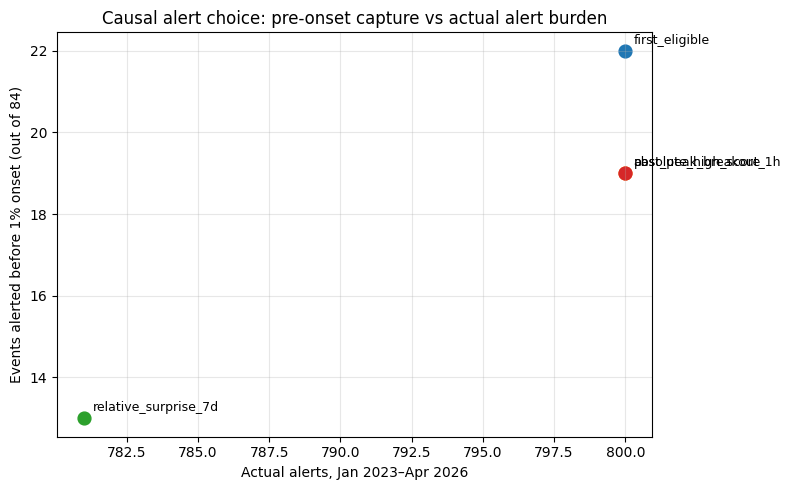

All result files saved: /content/drive/MyDrive/btc_lead_cost_results_77months_spot/causal_alert_selection_v1


In [11]:
# Plot: actual alarm burden is on x-axis, no artificially equalizing ex-post counts.
fig,ax=plt.subplots(figsize=(8,5))
for row in res.itertuples(index=False):
    ax.scatter(row.alarms,row.before_1pct,s=85)
    ax.annotate(row.policy,(row.alarms,row.before_1pct),xytext=(6,5),textcoords='offset points',fontsize=9)
ax.set(xlabel='Actual alerts, Jan 2023–Apr 2026',
       ylabel='Events alerted before 1% onset (out of 83)',
       title='Causal alert choice: pre-onset capture vs actual alert burden')
ax.grid(alpha=.3);fig.tight_layout()
fig.savefig(OUT/'selection_preonset_vs_alerts.png',dpi=180)
plt.show()
print('All result files saved:',OUT)

## Interpretation
- All four policies use the same score model and online rules under the hard caps of 240 alerts a year and 20 a month; 2026 is a partial year.
- `spot_reference.json` stores the spot event count, thresholds and alert, catch and pre-onset counts of the first-eligible and absolute-high-score policies.
- `mcnemar_pre1pct_p` is a descriptive paired test on previously inspected data, not a confirmatory result, and events are not independent if crashes cluster.
- The oracle of notebook 04 is a clairvoyant upper bound at its own candidate threshold; a higher absolute cutoff can shrink its candidate set, so the gap to the oracle is not all schedulable loss.
- The selection rules use past scores, not past labels, and no daily or future-window maximum.